In [1]:
# Import used library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

In [2]:
# Reload the dataset
file_path = ".\Dataset\\my_data.csv"
df = pd.read_csv(file_path)
df.head()

<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\Thinkpad X13\AppData\Local\Temp\ipykernel_22108\2571201799.py:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  file_path = ".\Dataset\\my_data.csv"


,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,...,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score,payment_level,payment_volume
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,...,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,Standard,High payment,Medium payment
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,...,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,Standard,Low payment,Small payment
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,...,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,Good,High payment,Small payment
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,...,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,Standard,Low payment,Medium payment
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,...,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,Poor,High payment,Medium payment


## Feature Engineering

In [3]:
# Mapping ordinal variables including both feature and target variables
# Mapping rules
credit_map = {'Bad': 0, 'Poor': 0, 'Standard': 1, 'Good': 2}
df[['credit_mix', 'credit_score']] = df[['credit_mix', 'credit_score']].replace(credit_map, inplace = True)

payment_level_map = {'High payment': 0, 'Low payment': 1}
df['payment_level'] = df['payment_level'].replace(payment_level_map, inplace = True)

payment_volume_map = {'Small payment': 0, 'Medium payment':1, 'Large payment': 2}
df['payment_volume'] = df['payment_volume'].replace(payment_volume_map, inplace = True)

# Check if they are mapped or not
ordinal_var = ['credit_mix', 'payment_level', 'payment_volume', 'credit_score']

for var in ordinal_var:
    unique_values = df[var].unique()
    print(f'The unique values of column {var} is:')
    print(unique_values)

print('Original dataset before feature engineering:')
display(df.head(5))
print('Dataset after feature engineering:')
display(df.head(5))

The unique values of column credit_mix is:
[1 2 0]
The unique values of column payment_level is:
[0 1]
The unique values of column payment_volume is:
[1 0 2]
The unique values of column credit_score is:
[1 2 0]
Original dataset before feature engineering:


C:\Users\Thinkpad X13\AppData\Local\Temp\ipykernel_22108\2176899206.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[['credit_mix', 'credit_score']] = df[['credit_mix', 'credit_score']].replace(credit_map, inplace = True)
C:\Users\Thinkpad X13\AppData\Local\Temp\ipykernel_22108\2176899206.py:7: ChainedAssignmentError: A value i

,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,...,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score,payment_level,payment_volume
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,...,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,1,0,1
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,...,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,1,1,0
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,...,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,2,0,0
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,...,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,1,1,1
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,...,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,0,0,1


Dataset after feature engineering:


,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,...,last_loan_7,last_loan_6,last_loan_5,last_loan_4,last_loan_3,last_loan_2,last_loan_1,credit_score,payment_level,payment_volume
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,...,No Loan,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Debt Consolidation Loan,1,0,1
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,...,No Loan,No Loan,No Loan,Debt Consolidation Loan,Home Equity Loan,Auto Loan,Auto Loan,1,1,0
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,...,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,No Loan,2,0,0
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,...,No Loan,No Loan,No Loan,No Loan,Personal Loan,Student Loan,Home Equity Loan,1,1,1
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,...,No Loan,No Loan,Auto Loan,Mortgage Loan,Auto Loan,Payday Loan,Not Specified,0,0,1


In [14]:
# Create domain-specific variables

df = df.assign(debt_to_income = lambda x: x['total_emi_per_month']/x['monthly_inhand_salary'], # when x in assign(), x is df
                saving_ratio=lambda x: x['monthly_balance'] / x['monthly_inhand_salary']
)

selected_cols = [f'last_loan_{i}' for i in range(1,10)]

dict_loan = {'count_debt_consolidation_loan': 'Debt Consolidation Loan', 'count_auto_loan' : 'Auto Loan',
                'count_no_loan': 'No Loan', 'count_home_equity_loan': 'Home Equity Loan', 'count_not_specified': 'Not Specified',
                'count_personal_loan': 'Personal Loan', 'count_mortgage_loan': 'Mortgage Loan', 'count_credit_builder_loan': 'Credit Builder Loan', 
                'count_payday_loan':'Payday Loan', 'count_student_loan':'Student Loan'}

for key, value in dict_loan.items():
    df[key] = (df[selected_cols] == value).sum(axis = 1)

active_loan_cols = [
    col for col in dict_loan.keys()
    if col not in ['count_no_loan', 'count_not_specified']
]

df['total_active_loans'] = df[active_loan_cols].sum(axis = 1)

# Binary flag indicators

# Red flag
df['has_payday_loan'] = (df['count_payday_loan'] > 0).astype(int)
df['has_home_equity_loan'] = (df['count_home_equity_loan'] > 0).astype(int)
df['has_mortgage_loan'] = (df['count_mortgage_loan'] > 0).astype(int)

# Green flag
df['has_credit_builder_loan'] = (df['count_credit_builder_loan'] > 0).astype(int)

df['high_risk_loan_ratio'] = (df['count_payday_loan'])/(df['total_active_loans'] + 1)

df = df.drop(columns = selected_cols)

df.head()

,customer_id,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,...,count_mortgage_loan,count_credit_builder_loan,count_payday_loan,count_student_loan,total_active_loans,has_payday_loan,has_home_equity_loan,has_mortgage_loan,has_credit_builder_loan,high_risk_loan_ratio
0,CUS_0x98ed,31,Journalist,22229.060,1672.421667,6,4,5.0,3,10,...,0,0,0,0,3,0,1,0,0,0.0
1,CUS_0x36b4,43,Musician,17060.705,1685.725417,8,3,11.0,4,24,...,0,0,0,0,4,0,1,0,0,0.0
2,CUS_0x105b,24,Accountant,34428.210,2575.017500,2,4,8.0,0,3,...,0,0,0,0,0,0,0,0,0,0.0
3,CUS_0x4c4a,21,Accountant,12613.920,1155.160000,4,6,13.0,3,14,...,0,0,0,1,3,0,1,0,0,0.0
4,CUS_0x612f,31,Journalist,34775.160,3048.930000,7,9,25.0,5,20,...,1,0,1,0,4,1,0,1,0,0.2


In [5]:
# test

df['last_loan_1'].unique()

<StringArray>
['Debt Consolidation Loan',               'Auto Loan',
                 'No Loan',        'Home Equity Loan',
           'Not Specified',           'Personal Loan',
           'Mortgage Loan',     'Credit-Builder Loan',
             'Payday Loan',            'Student Loan']
Length: 10, dtype: str

### Correlation between type of feature variables and target variable

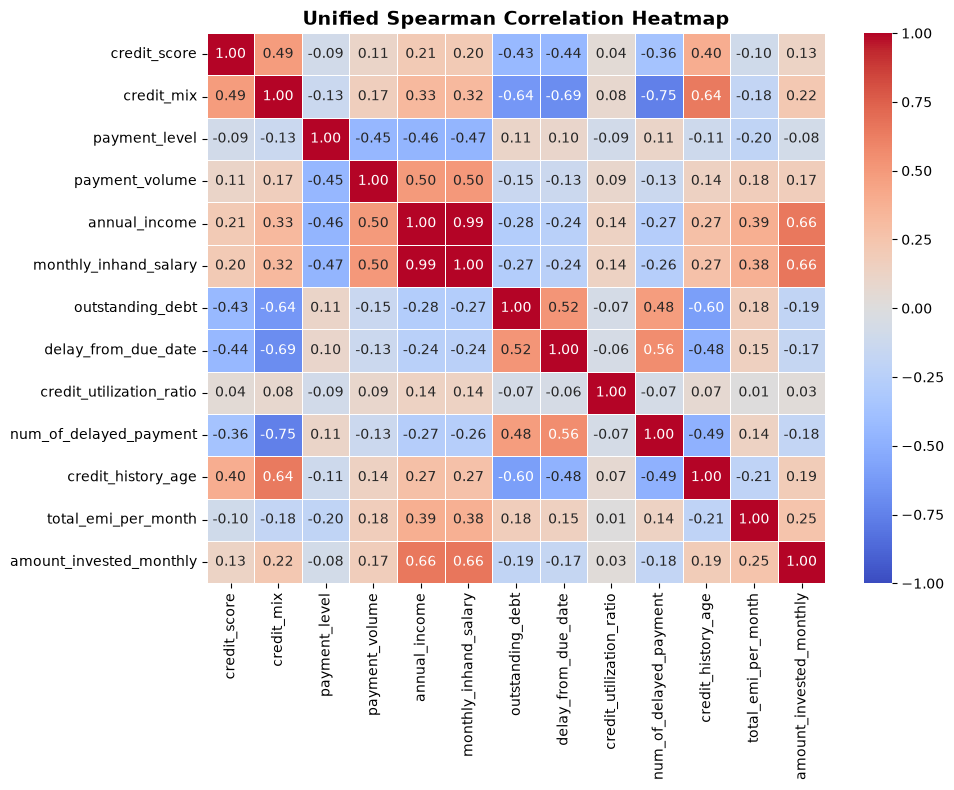

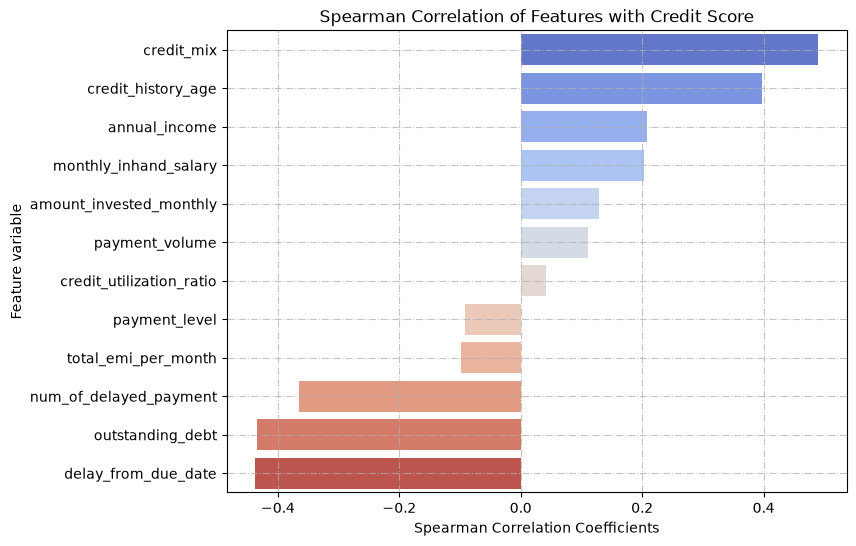

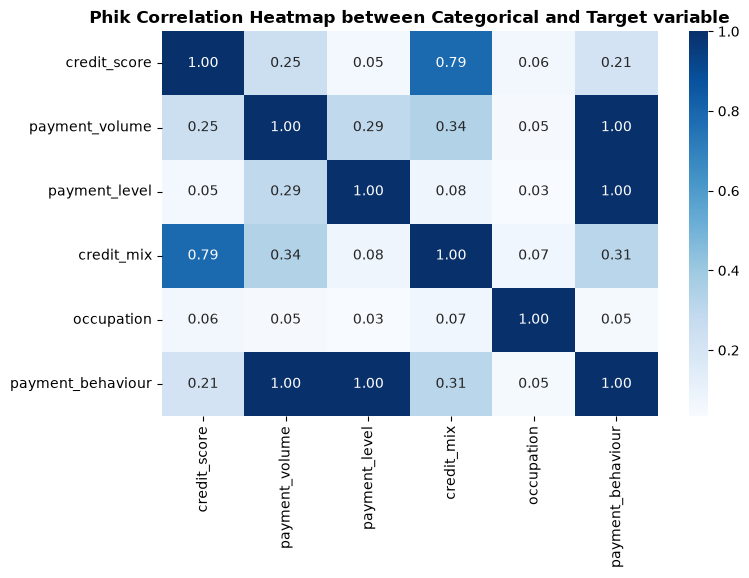

In [6]:
# Prepare dataframe for creating heatmaps
all_numeric_cols = [
    'credit_score', 'credit_mix', 'payment_level', 'payment_volume', 
    'annual_income', 'monthly_inhand_salary', 'outstanding_debt', 'delay_from_due_date', 
    'credit_utilization_ratio', 'num_of_delayed_payment', 
    'credit_history_age', 'total_emi_per_month', 'amount_invested_monthly'
]

spearman_corr = df[all_numeric_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Unified Spearman Correlation Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Target correlation plot

target_corr = spearman_corr[['credit_score']].drop(index = 'credit_score').sort_values(by = 'credit_score', ascending = False)
plt.figure(figsize=(8,6))

sns.barplot(data = target_corr, x = 'credit_score', y = target_corr.index, palette = 'coolwarm', hue = target_corr.index)
plt.title("Spearman Correlation of Features with Credit Score")
plt.xlabel("Spearman Correlation Coefficients")
plt.ylabel("Feature variable")

plt.grid(True, linestyle = '-.', alpha = 0.75)
plt.show()

# Using phik to check correlation between nominal and target variables

phik_temp1 = df[['credit_score', 'payment_volume', 'payment_level', 'credit_mix']]
phik_temp2 = df[['occupation', 'payment_behaviour']]
phik_matrix = pd.concat([phik_temp1, phik_temp2], axis = 1).phik_matrix()

plt.figure(figsize = (8, 5))
sns.heatmap(data = phik_matrix, annot = True, fmt = '.2f', cmap = 'Blues')
plt.title('Phik Correlation Heatmap between Categorical and Target variable', fontweight = 'bold')
plt.show()